# **Hotel Suitability Analysis**
## **A python-based Multi-Criteria Decision Analysis for suitable hotel location in Lisbon, Portugal**

### **Client Brief**

A tourism company wants to build a hotel in Lisbon. They set specified
requirements for their construction, namely:

1. It should be away from streets at least 20 metres.
2. It should be built in an area that is not occupied by buildings, wetlands or water.
3. It should be built in an area with a slope <10%.
4. The hotel and adjacent areas should occupy an area of at least 1 hectares.
5. The suitability areas should be inside Lisbon urbanization plan areas.

The goal is to answer the question: **Where to build a hotel?**

### **Imports & Configuration**

In [26]:
# Import Libraries

import geopandas as gpd
import rasterio
from rasterio import features
from rasterio.enums import Resampling
from rasterio.warp import reproject, Resampling
from rasterio.transform import from_origin
from rasterio.features import shapes
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from shapely.geometry import shape

import warnings


In [15]:
# Define paths and parameters

# Paths

DATA = Path("data")
OUT  = Path("outputs"); OUT.mkdir(exist_ok=True)

ROADS_FP = DATA / "Lx_Streets" / "gis_osm_roads_free_1.shp"
DEM_FP     = DATA / "Lx_elevation" / "elevation_lx.tif"
PARISH_FP  = DATA / "Lx_parishes" / "Lx_parishes.shp"
LANDC_FP   = DATA / "Lx_land_cover" / "Lx_land_cover_N5.shp"
URBAN_FP   = DATA / "Lx_urbanization_plan" / "Limit_urban_plan.shp"

# Model Parameters

CRS = "EPSG:3763"      # ETRS_1989_Portugal_TM06 / ETRS89
CELL_SIZE  = 20              # output raster resolution (m)
ROAD_BUFF  = 20              # min distance from streets (m)
SLOPE_MAX  = 10             # max slope (%)
MIN_AREA   = 10000          # min contiguous suitable area (m^2) = 1 ha

# Weights for the Weighted Sum (from client brief)

W_ROADS    = 1.0
W_LANDC    = 2.0
W_SLOPE    = 1.25

### **Data Loading and Validation (Vector data)**

In [7]:
roads   = gpd.read_file(ROADS_FP)
parishes = gpd.read_file(PARISH_FP)
landcover = gpd.read_file(LANDC_FP)
urban   = gpd.read_file(URBAN_FP)

for name, gdf in [("roads", roads), ("parishes", parishes),
                  ("landcover", landcover), ("urban", urban)]:
    # Ensure CRS is set to EPSG:3763
    if gdf.crs is None:
        gdf.set_crs(CRS, inplace=True)
    elif gdf.crs.to_string() != CRS:
        gdf.to_crs(CRS, inplace=True)
    print(f"{name:10s}: {len(gdf):6d} features | CRS={gdf.crs.to_epsg()}")

print("\nLand cover columns:", list(landcover.columns))
landcover.head()

roads     : 872345 features | CRS=3763
parishes  :     24 features | CRS=3763
landcover :   1021 features | CRS=3763
urban     :     20 features | CRS=3763

Land cover columns: ['COSN5', 'ID', 'AREA', 'PERIMETER', 'COS_N1', 'code', 'geometry']


,COSN5,ID,AREA,PERIMETER,COS_N1,code,geometry
0,1.1.1.01.1,281,9.449804,1549.8,1,NaN,"POLYGON ((-93738.750 -107273.260, -93706.910 -..."
1,1.1.1.01.1,283,2.447456,719.0,1,NaN,"POLYGON ((-92990.070 -107181.770, -92975.010 -..."
2,1.1.1.01.1,293,53.132401,4399.2,1,NaN,"POLYGON ((-95062.340 -107227.250, -95049.990 -..."
3,1.1.1.01.1,295,3.435971,988.0,1,NaN,"POLYGON ((-95074.550 -106709.900, -95077.660 -..."
4,1.1.1.01.1,317,29.186431,3871.9,1,NaN,"POLYGON ((-90985.750 -106218.440, -90961.550 -..."


### **Definition of Analysis Grid (Raster)**

Every reclassified raster will be based on a common grid derived from the parishes extent so they align perfectly for next steps.

In [16]:
# Use the parishes layer as the study-area boundary
study_area = parishes.dissolve()             
minx, miny, maxx, maxy = study_area.total_bounds

# Snap bounds to the cell size
minx = np.floor(minx / CELL_SIZE) * CELL_SIZE
miny = np.floor(miny / CELL_SIZE) * CELL_SIZE
maxx = np.ceil(maxx  / CELL_SIZE) * CELL_SIZE
maxy = np.ceil(maxy  / CELL_SIZE) * CELL_SIZE

n_cols = int((maxx - minx) / CELL_SIZE)
n_rows = int((maxy - miny) / CELL_SIZE)

transform = from_origin(minx, maxy, CELL_SIZE, CELL_SIZE)

profile = {
    "driver": "GTiff",
    "dtype": "float32",
    "nodata": -9999,
    "width": n_cols,
    "height": n_rows,
    "count": 1,
    "crs": CRS,
    "transform": transform,
}
print(f"Grid: {n_rows} rows x {n_cols} cols @ {CELL_SIZE} m")

# Mask of cells inside the study area (used to clip every layer)
study_mask = features.rasterize(
    [(geom, 1) for geom in study_area.geometry],
    out_shape=(n_rows, n_cols),
    transform=transform,
    fill=0,
    dtype="uint8",
).astype(bool)

def save_raster(array, path, profile=profile):
    """Write a 2D array to GeoTIFF with the model profile."""
    p = profile.copy()
    with rasterio.open(path, "w", **p) as dst:
        dst.write(array.astype("float32"), 1)
    print("saved", path)

Grid: 643 rows x 667 cols @ 20 m


### **Criterion 1: Distance from roads (>= 20m)**

The roads will be clipped to the study area. A buffer of 20 m will be applied and the result rasterize. The cells will undergo binary reclassification where cells outside the buffer = 1 (suitable) and cells inside the buffer= 0.

In [17]:
# Clip roads to study area
roads_clip = gpd.clip(roads, study_area)

# Buffer 20 m
road_buffer = roads_clip.buffer(ROAD_BUFF)

# Rasterize buffer: 1 where road buffer exists
buffer_rast = features.rasterize(
    [(geom, 1) for geom in road_buffer if geom is not None and not geom.is_empty],
    out_shape=(n_rows, n_cols),
    transform=transform,
    fill=0,
    dtype="uint8",
)

# Reclassify: inside buffer (1) -> 0 ; outside buffer (0) -> 1
reclass_roads = np.where(buffer_rast == 1, 0, 1).astype("float32")
reclass_roads[~study_mask] = profile["nodata"]

save_raster(reclass_roads, OUT / "reclass_roads.tif")

saved outputs\reclass_roads.tif


### **Criterion 2: land cover (keep agriculture & forest/natural)**

The level-1 code (first digit of the N5 class code) will be derived. The classes 2 (Agriculture) and 3 (Forests & natural vegetation) will be kept while excluding 1 (artificial), 4 (wetlands) and 5 (water).

In [18]:
# Identify the land-cover code field
# Common names: 'COSN5', 'COS_N5', 'Cod_N5'.
CODE_FIELD = "COSN5"          
assert CODE_FIELD in landcover.columns, \
    f"Set CODE_FIELD to one of: {list(landcover.columns)}"

# Level-1 code = first character of the N5 code
landcover["level1"] = landcover[CODE_FIELD].astype(str).str.strip().str[0].astype(int)

# Suitable = agriculture (2) and forest/natural (3)
landcover["lc_suit"] = landcover["level1"].isin([2, 3]).astype(int)

# Rasterize the suitability value
reclass_landcover = features.rasterize(
    [(geom, val) for geom, val in zip(landcover.geometry, landcover["lc_suit"])],
    out_shape=(n_rows, n_cols),
    transform=transform,
    fill=0,
    dtype="uint8",
).astype("float32")

reclass_landcover[~study_mask] = profile["nodata"]
save_raster(reclass_landcover, OUT / "reclass_landcover.tif")

saved outputs\reclass_landcover.tif


### **Criterion 3: slope (< 10 %)**

The slope will be computed (in percent) from the DEM. It will be resampled to the 20 m grid and then reclassified in the following category: 0–10 % = 1, >10 % = 0.

In [19]:
# Read DEM (nodata -> NaN)
with rasterio.open(DEM_FP) as src:
    dem = src.read(1, masked=True).astype("float64").filled(np.nan)
    dem_transform = src.transform
    dem_crs = src.crs
    xres, yres = src.res          # pixel size in CRS units (must be metres)

assert dem_crs.is_projected, "DEM must be in a projected CRS (metres) for slope in %"


# Slope (%) at native resolution, Horn's method
zp = np.pad(dem, 1, mode="edge")
a, b, c = zp[:-2, :-2], zp[:-2, 1:-1], zp[:-2, 2:]
d,    f = zp[1:-1, :-2],               zp[1:-1, 2:]
g, h, i = zp[2:, :-2],  zp[2:, 1:-1],  zp[2:, 2:]

dzdx = ((c + 2*f + i) - (a + 2*d + g)) / (8 * xres)
dzdy = ((g + 2*h + i) - (a + 2*b + c)) / (8 * yres)
slope_pct_native = (np.hypot(dzdx, dzdy) * 100.0).astype("float32")

print(f"Native slope: {np.nanmin(slope_pct_native):.1f} – "
      f"{np.nanmax(slope_pct_native):.1f} %")


# Resample slope onto the 20 m analysis grid
slope_grid = np.full((n_rows, n_cols), np.nan, dtype="float32")
reproject(
    source=slope_pct_native,
    destination=slope_grid,
    src_transform=dem_transform, src_crs=dem_crs, src_nodata=np.nan,
    dst_transform=transform,     dst_crs=CRS,     dst_nodata=np.nan,
    resampling=Resampling.bilinear,
)


# Reclassify: 0–10 % -> 1, >10 % -> 0
reclass_slope = np.where((slope_grid >= 0) & (slope_grid <= SLOPE_MAX), 1, 0).astype("float32")
reclass_slope[~study_mask] = profile["nodata"]


# check for study-area cells with no DEM data
n_missing = np.count_nonzero(np.isnan(slope_grid) & study_mask)
if n_missing:
    print(f"Warning: {n_missing} study-area cells have no slope value (set to 0)")

save_raster(reclass_slope, OUT / "reclass_slope.tif")

Native slope: 0.0 – 48.3 %
saved outputs\reclass_slope.tif


### **Combine criteria (simple sum)**

The Raster Calculator sum will be implemented. A value of 3 would indicate that all three criteria are satisfied.

saved outputs\sum_criteria.tif


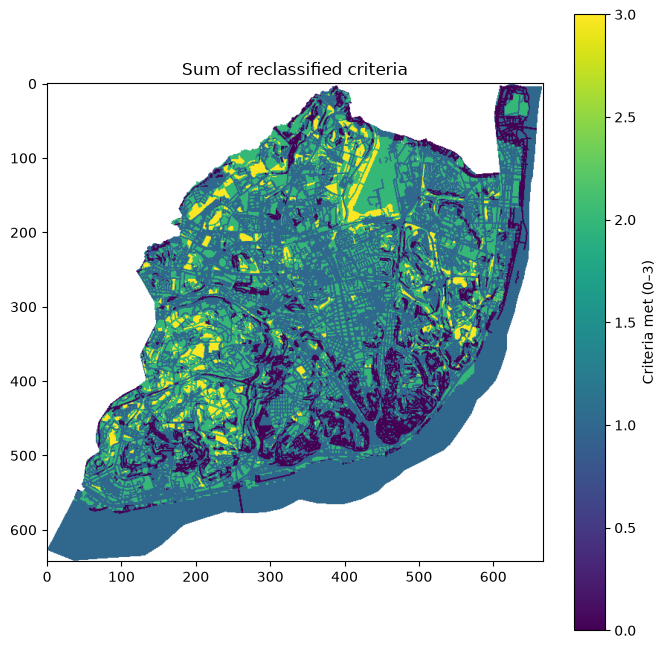

In [20]:
valid = study_mask  # cells to keep

stack_sum = np.where(
    valid,
    reclass_roads * (reclass_roads != profile["nodata"])
    + reclass_landcover * (reclass_landcover != profile["nodata"])
    + reclass_slope * (reclass_slope != profile["nodata"]),
    profile["nodata"],
).astype("float32")

save_raster(stack_sum, OUT / "sum_criteria.tif")

# quick look
plt.figure(figsize=(8, 8))
show = np.where(valid, stack_sum, np.nan)
plt.imshow(show, cmap="viridis")
plt.colorbar(label="Criteria met (0–3)")
plt.title("Sum of reclassified criteria")
plt.show()

### **Weighted Sum**

The following weights would be applied (roads = 1, land cover = 2, slope = 1.25)

saved outputs\weighted_sum.tif
Maximum possible weighted score: 4.25


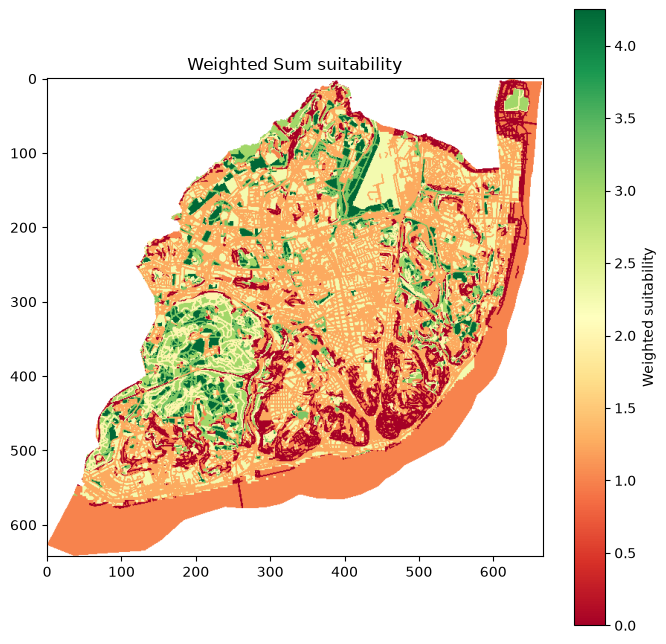

In [21]:
def m(arr):
    """Mask nodata to 0 so it doesn't pollute the weighted sum."""
    return np.where(arr == profile["nodata"], 0, arr)

weighted = (W_ROADS * m(reclass_roads)
            + W_LANDC * m(reclass_landcover)
            + W_SLOPE * m(reclass_slope)).astype("float32")

weighted[~study_mask] = profile["nodata"]
save_raster(weighted, OUT / "weighted_sum.tif")

max_score = W_ROADS + W_LANDC + W_SLOPE
print("Maximum possible weighted score:", max_score)

plt.figure(figsize=(8, 8))
plt.imshow(np.where(study_mask, weighted, np.nan), cmap="RdYlGn")
plt.colorbar(label="Weighted suitability")
plt.title("Weighted Sum suitability")
plt.show()

### **Conversion of Raster to polygons & area filter (>= 1 ha)**

Fully-suitable cells (all criteria met) will be kept and converted to polygons. Contiguous areas would be dissolved and areas greater than 1 hectare (1 ha) would be kept.

In [22]:
# Fully suitable = all three criteria met (sum == 3)
fully_suitable = np.where(study_mask & (stack_sum == 3), 1, 0).astype("uint8")

# Vectorize the suitable cells
geoms = []
for geom, val in shapes(fully_suitable, mask=fully_suitable.astype(bool),
                        transform=transform):
    if val == 1:
        geoms.append(shape(geom))

suit = gpd.GeoDataFrame(geometry=geoms, crs=CRS)

# Dissolve adjacent cells into contiguous regions, then split to single parts
suit_dissolved = suit.dissolve().explode(index_parts=False).reset_index(drop=True)
suit_dissolved["area_m2"] = suit_dissolved.area

# Keep regions >= 1 ha
candidates = suit_dissolved[suit_dissolved["area_m2"] >= MIN_AREA].copy()
print(f"{len(candidates)} candidate areas >= {MIN_AREA/10000:.1f} ha")

candidates.to_file(OUT / "candidate_areas.shp")

125 candidate areas >= 1.0 ha


### **Criterion 4: keep suitable candidates within the urbanization plan**

In [23]:
urban_union = urban.dissolve()

# keep candidate areas completely within the urbanization plan
within_mask = candidates.within(urban_union.geometry.iloc[0])
final = candidates[within_mask].copy()

# attach the mean weighted suitability score per area (zonal stats)
from rasterstats import zonal_stats
stats = zonal_stats(final, weighted, affine=transform, nodata=profile["nodata"],
                    stats=["mean", "max"])
final["score_mean"] = [s["mean"] for s in stats]
final["score_max"]  = [s["max"]  for s in stats]

final = final.sort_values("area_m2", ascending=False).reset_index(drop=True)
print(f"{len(final)} final suitable hotel locations")
final[["area_m2", "score_mean", "score_max"]].head(10)

final.to_file(OUT / "hotel_suitable_sites.shp")

19 final suitable hotel locations


### **Final Map**

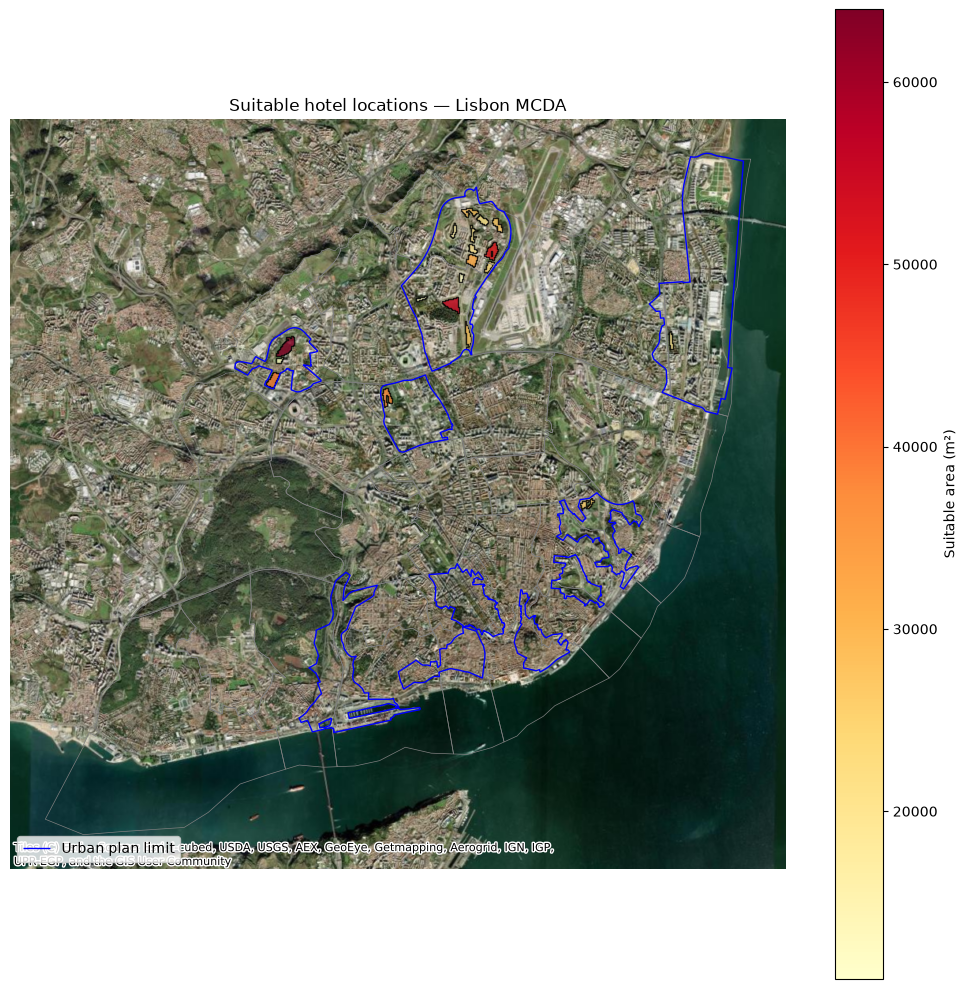

In [27]:
import matplotlib.pyplot as plt

# Optional basemap: works with or without contextily installed
try:
    import contextily as ctx
    HAS_CTX = True
except ImportError:
    HAS_CTX = False
    print("contextily not installed – plotting without basemap")

fig, ax = plt.subplots(figsize=(10, 10))
parishes.boundary.plot(ax=ax, color="grey", linewidth=0.5)
urban_union.boundary.plot(ax=ax, color="blue", linewidth=1, label="Urban plan limit")
final.plot(ax=ax, column="area_m2", cmap="YlOrRd", legend=True,
           edgecolor="black", alpha=0.8,
           legend_kwds={"label": "Suitable area (m²)"})

ax.legend(loc="lower left")   # shows the "Urban plan limit" line label
ax.set_title("Suitable hotel locations — Lisbon MCDA")
ax.set_axis_off()


# Add basemap last so it matches the final map extent
if HAS_CTX:
    providers = [
        ctx.providers.Esri.WorldImagery,
        ctx.providers.OpenStreetMap.Mapnik,
    ]
    for prov in providers:
        try:
            with warnings.catch_warnings():
                warnings.simplefilter("error")   # treat API-key warnings as failures
                ctx.add_basemap(ax, crs=CRS, source=prov)
            break                                # success, stop trying
        except Exception as e:
            print(f"Basemap '{prov.name}' skipped: {e}")
    else:
        print("No basemap could be added – map drawn without one")


plt.tight_layout()
plt.savefig(OUT / "hotel_suitability_map.png", dpi=200)
plt.show()

### **Findings**

**1. Initial suitability assessment**

The analysis identified **125 candidate** areas of at least **1 hectare** that satisfied all three initial suitability criteria: distance from roads, acceptable land cover, and slope below or equal to 10%.


**2. Urbanisation plan restriction**

After restricting the candidates to areas completely within the urbanisation plan, **19 suitable hotel locations** remained. This is a reduction of 106 candidate areas, or approximately 84.8%, following the spatial constraint.


**3. Spatial analysis framework**

The study used a common raster grid with a **20-metre** cell size, allowing the criteria to be aligned and combined consistently across the study area.


**Additional findings from the suitability criteria**

1. Areas within 20 metres of mapped roads were classified as unsuitable, while areas outside the road buffers received a suitability value of 1. This criterion prioritises separation from roads rather than direct proximity to them.

2. Agricultural land and forests or natural vegetation were retained as suitable classes. Artificial surfaces, wetlands, and water were excluded.

3. Areas with slopes between 0% and 10% were considered suitable. The computed slope ranged from 0% to 48.3%, indicating variation in terrain conditions across the study area.

4. The notebook assigned weights of 1.0 to roads, 2.0 to land cover, and 1.25 to slope, giving a maximum theoretical weighted score of 4.25. However, the final candidate selection was based on satisfying all three binary criteria, not on ranking locations by the weighted score.

### **Conclusion**

The analysis identified 19 potentially suitable hotel locations in Lisbon, reduced from 125 initial candidates after applying urbanisation plan restrictions. The Python-based GIS and MCDA workflow provides a reproducible approach to site selection. However, missing DEM-derived slope data and further validation of suitability criteria must be addressed before confirming the results. Additional factors, such as public transport accessibility and proximity to tourist attractions, could improve the assessment.